In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
df=pd.read_csv("nassau_candy.csv")
df.shape

(10194, 18)

In [2]:
# Create the geographic proxy route
df["Region_State_Route"]=(
    df["Region"].astype("string").str.strip()
    + "->"
    + df["State/Province"].astype("string").str.strip()
)
print(df["Region_State_Route"].head(10))
print("Unique geographic routes:", df["Region_State_Route"].nunique())

0           Interior->Texas
1        Interior->Illinois
2        Interior->Illinois
3        Interior->Illinois
4    Atlantic->Pennsylvania
5            Gulf->Kentucky
6            Gulf->Kentucky
7             Gulf->Georgia
8            Gulf->Kentucky
9            Gulf->Kentucky
Name: Region_State_Route, dtype: string
Unique geographic routes: 59


In [3]:
# Aggregate rout-level business performance
route_summary=(
    df.groupby(
        ["Region","State/Province","Region_State_Route"], dropna=False
    )
    .agg(
        Record_Count=("Row ID","count"),
        Distinct_Orders=("Order ID","nunique"),
        Sales=("Sales","sum"),
        Units=("Units","sum"),
        Gross_Profit=("Gross Profit","sum"),
        cost=("Cost","sum")
    )
    .reset_index()

)
route_summary["Gross_Profit_Margin_Pct"]=(
    route_summary["Gross_Profit"]
    .div(route_summary["Sales"].replace
         (0,np.nan))
         .mul(100)
)
route_summary=route_summary.sort_values(
    "Sales", ascending=False
)
print(route_summary.head(20).to_string(index=False))

  Region State/Province      Region_State_Route  Record_Count  Distinct_Orders    Sales  Units  Gross_Profit    cost  Gross_Profit_Margin_Pct
 Pacific     California     Pacific->California          2001             1686 27917.40   7667      18479.42 9437.98                66.193199
Atlantic       New York      Atlantic->New York          1128              942 15541.03   4224      10222.44 5318.59                65.777107
Interior          Texas         Interior->Texas           985              833 13416.09   3724       8909.53 4506.56                66.409289
Atlantic   Pennsylvania  Atlantic->Pennsylvania           587              487  8027.03   2153       5225.47 2801.56                65.098424
 Pacific     Washington     Pacific->Washington           506              432  6921.15   1883       4566.64 2354.51                65.980942
Interior       Illinois      Interior->Illinois           492              433  6898.96   1845       4557.68 2341.28                66.063291
Atlant

In [11]:
# Identify high-volume geographic groups
route_by_volume =(
route_summary.sort_values(
    "Record_Count",ascending=False
))
print(
    route_by_volume[
    ["Region_State_Route",
        "Record_Count",
        "Distinct_Orders",
        "Sales",
        "Gross_Profit"
    ]
].head(10).to_string(index=False))

    Region_State_Route  Record_Count  Distinct_Orders    Sales  Gross_Profit
   Pacific->California          2001             1686 27917.40      18479.42
    Atlantic->New York          1128              942 15541.03      10222.44
       Interior->Texas           985              833 13416.09       8909.53
Atlantic->Pennsylvania           587              487  8027.03       5225.47
   Pacific->Washington           506              432  6921.15       4566.64
    Interior->Illinois           492              433  6898.96       4557.68
        Atlantic->Ohio           469              392  6768.95       4413.03
         Gulf->Florida           383              319  4804.02       3207.11
    Interior->Michigan           255              209  3331.00       2236.21
  Gulf->North Carolina           249              216  3450.86       2331.16


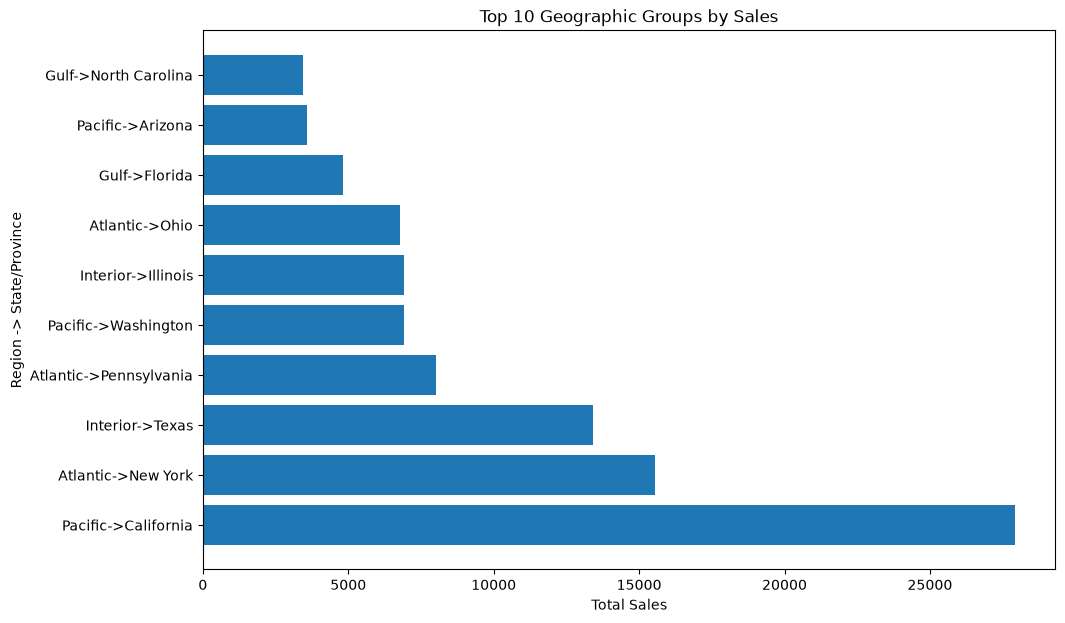

In [13]:
# Visualize the top 10 geographic groups
top_routes =(
route_summary.sort_values("Sales",ascending=False).head(10))
plt.figure(figsize=(11,7))
plt.barh(
    top_routes["Region_State_Route"],
    top_routes["Sales"]
)

plt.title("Top 10 Geographic Groups by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Region -> State/Province")
plt.show()

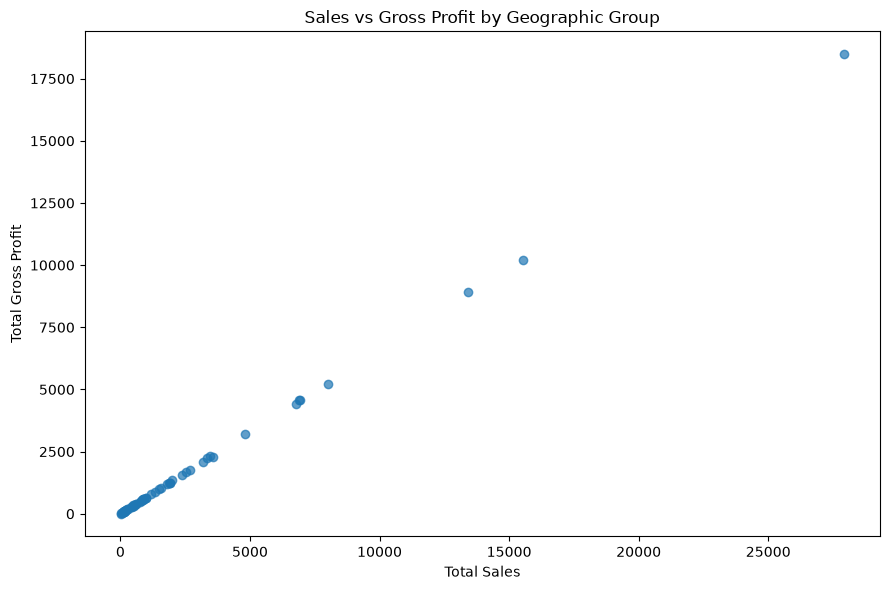

In [14]:
# Compare sales with gross profit
plt.figure(figsize=(9,6))
plt.scatter(
    route_summary["Sales"],
    route_summary["Gross_Profit"],
    alpha=0.7
)
plt.title("Sales vs Gross Profit by Geographic Group")
plt.xlabel("Total Sales")
plt.ylabel("Total Gross Profit")
plt.tight_layout()
plt.show()